<a href="https://colab.research.google.com/github/rachamadaci-cell/TP1/blob/main/TP1%20(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3
Matplotlib: 3.10.0
Seaborn: 0.13.2


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [3]:
# Write your code here
import numpy as np
S =np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + bias

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1 / (1 + np.exp(-z))

# Identify predicted spam emails
predicted_spam = probabilities >= 0.5

In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [5]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [9]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Write your code here
idx = rng.choice(log.index, size=12, replace=False)
log.loc[idx, 'failed_attempts'] = rng.integers(5, 11, size=12)

In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [10]:
# Insert 10 missing values randomly

# Write your code here
missing_rows = rng.choice(log.index, size=10, replace=False)
for r in missing_rows:
    col = rng.choice(log.columns)
    log.loc[r, col] = np.nan

In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [12]:
# Write your code here

# ru_log_at_least_five_attempts = ...
ru_log_at_least_five_attempts = ((log['country'] == 'RU') & (log['failed_attempts'] >= 5)).sum()


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [13]:
# Write your code here
user_max_failed_attempts = log.groupby('user')['failed_attempts'].sum().sort_values(ascending=False).index[0]
# user_max_failed_attempts =

In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [14]:
# Write your code here
log['long_session'] = (log['duration_min'] > 30).astype(int)
# log['long_session'] = ...

In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

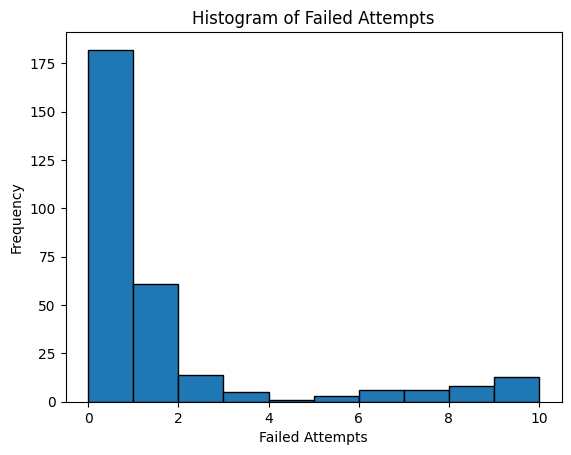

In [17]:
# Draw the histogram of failed_attempts.
# Write your code here
import matplotlib.pyplot as plt
plt.hist(log['failed_attempts'].dropna(), edgecolor='black')
plt.title('Histogram of Failed Attempts')
plt.xlabel('Failed Attempts')
plt.ylabel('Frequency')
plt.show()


In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [21]:
# Write your code here
# answer_q2 = B


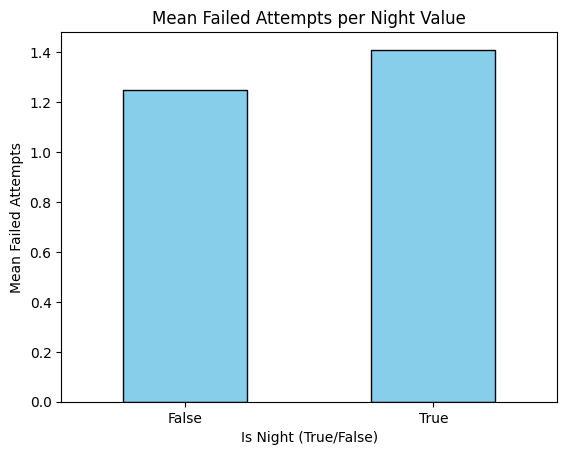

In [20]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
import matplotlib.pyplot as plt
mean_failed_per_night = log.groupby(log['hour'].between(0, 6))['failed_attempts'].mean()

mean_failed_per_night.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Mean Failed Attempts per Night Value')
plt.xlabel('Is Night (True/False)')
plt.ylabel('Mean Failed Attempts')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code
"""
It returns all values of the 3rd column for all 300 rows as a 1D array.
"""

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [ ]:
# Write your code here
df.isna().sum()

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
# Write your code here
"""
A boxplot or a bar chart comparing failed attempts by country.
"""

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
"""
A boxplot or a bar chart comparing failed attempts by country.
"""


Commit the logins_clean.csv.(0.5 point)

In [ ]:
# save the cleaned table in login_clean.csv
# Write your code here
log.to_csv('logins_clean.csv', index=False)

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [1]:
# Write your code here
import pandas as pd
import numpy as np
cols = ['hour', 'failed_attempts', 'duration_min', 'night']
if 'night' not in log.columns:
    log['night'] = log['hour'].between(0, 6).astype(int)

X = log[cols].to_numpy()
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)
print(X_scaled.shape)

NameError: name 'pd' is not defined

In [ ]:
import numpy as np
import pandas as pd
